In [1]:
%pip install pandas numpy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import io
import zipfile
import urllib.request
import pandas as pd

url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

with urllib.request.urlopen(url) as response:
    archive_data = response.read()

with zipfile.ZipFile(io.BytesIO(archive_data)) as archive:
    csv_name = next(name for name in archive.namelist()
                    if name.endswith("bank-additional-full.csv"))
    df = pd.read_csv(archive.open(csv_name), sep=";")

print("Dataset loaded:", df.shape)
df.head()

StopIteration: 

In [3]:
with zipfile.ZipFile(io.BytesIO(archive_data)) as archive:
    print(archive.namelist()[:30])

['bank.zip', 'bank-additional.zip']


In [4]:
with zipfile.ZipFile(io.BytesIO(archive_data)) as outer:
    inner_zip_data = outer.read("bank-additional.zip")

with zipfile.ZipFile(io.BytesIO(inner_zip_data)) as inner:
    csv_name = next(name for name in inner.namelist()
                    if name.endswith("bank-additional-full.csv"))
    df = pd.read_csv(inner.open(csv_name), sep=";")

print("Dataset loaded:", df.shape)
df.head()

Dataset loaded: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [5]:
print("Rows and columns:", df.shape)

display(df.head())

print("Subscription counts:")
display(df["y"].value_counts())

print("Subscription percentages:")
display((df["y"].value_counts(normalize=True) * 100).round(2))

print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).head(10))

Rows and columns: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Subscription counts:


y
no     36548
yes     4640
Name: count, dtype: int64

Subscription percentages:


y
no     88.73
yes    11.27
Name: proportion, dtype: float64

Missing values by column:


age            0
job            0
marital        0
education      0
default        0
housing        0
loan           0
contact        0
month          0
day_of_week    0
dtype: int64

In [6]:
# 1 means subscribed; 0 means did not subscribe
y = (df["y"] == "yes").astype(int)

# Exclude the outcome and call duration from the input features
X = df.drop(columns=["y", "duration"])

# Use the earlier 80% of rows for training and the later 20% for evaluation
split_at = int(len(df) * 0.80)

X_train = X.iloc[:split_at]
X_test = X.iloc[split_at:]
y_train = y.iloc[:split_at]
y_test = y.iloc[split_at:]

print("Training rows:", len(X_train))
print("Evaluation rows:", len(X_test))
print("Subscriber rate in training data:", round(y_train.mean() * 100, 2), "%")
print("Subscriber rate in evaluation data:", round(y_test.mean() * 100, 2), "%")
print("Features used:", X.columns.tolist())

Training rows: 32950
Evaluation rows: 8238
Subscriber rate in training data: 6.37 %
Subscriber rate in evaluation data: 30.83 %
Features used: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


In [7]:
period = ["Training" if i < split_at else "Evaluation"
          for i in range(len(df))]

month_summary = df.assign(
    period=period,
    subscribed=(df["y"] == "yes")
).groupby(["period", "month"]).agg(
    customers=("y", "size"),
    subscriptions=("subscribed", "sum"),
    response_rate=("subscribed", "mean")
).reset_index()

print("Response rate by month:")
display(month_summary.pivot(
    index="month", columns="period", values="response_rate"
).round(3))

print("Number of records by month and period:")
display(month_summary.pivot(
    index="month", columns="period", values="customers"
).fillna(0).astype(int))

Response rate by month:


period,Evaluation,Training
month,,
apr,0.557,0.180
aug,0.383,0.052
dec,0.512,0.100
jul,0.495,0.061
jun,0.393,0.043
mar,0.568,0.447
may,0.130,0.042
nov,0.466,0.053
oct,0.419,0.627


Number of records by month and period:


period,Evaluation,Training
month,,
apr,174,2458
aug,1003,5175
dec,172,10
jul,489,6685
jun,944,4374
mar,264,282
may,3486,10283
nov,485,3616
oct,651,67


In [8]:
from sklearn.model_selection import train_test_split

X_train_random, X_test_random, y_train_random, y_test_random = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training subscriber rate:",
      round(y_train_random.mean() * 100, 2), "%")
print("Evaluation subscriber rate:",
      round(y_test_random.mean() * 100, 2), "%")

Training subscriber rate: 11.27 %
Evaluation subscriber rate: 11.26 %


In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_random, y_train_random)

baseline_predictions = baseline.predict(X_test_random)

print("Confusion matrix:")
print(confusion_matrix(y_test_random, baseline_predictions))

print("\nClassification report:")
print(classification_report(
    y_test_random,
    baseline_predictions,
    target_names=["No subscription", "Subscribed"],
    zero_division=0
))

Confusion matrix:
[[7310    0]
 [ 928    0]]

Classification report:
                 precision    recall  f1-score   support

No subscription       0.89      1.00      0.94      7310
     Subscribed       0.00      0.00      0.00       928

       accuracy                           0.89      8238
      macro avg       0.44      0.50      0.47      8238
   weighted avg       0.79      0.89      0.83      8238



In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_columns = X_train_random.select_dtypes(include="object").columns
numeric_columns = X_train_random.select_dtypes(exclude="object").columns

preprocessor = ColumnTransformer([
    ("categories", Pipeline([
        ("fill_missing", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_columns),
    ("numbers", Pipeline([
        ("fill_missing", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numeric_columns)
])

model = Pipeline([
    ("prepare", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

model.fit(X_train_random, y_train_random)

predictions = model.predict(X_test_random)
probabilities = model.predict_proba(X_test_random)[:, 1]

print(classification_report(
    y_test_random,
    predictions,
    target_names=["No subscription", "Subscribed"],
    zero_division=0
))
print("PR-AUC:", round(average_precision_score(y_test_random, probabilities), 3))
print("ROC-AUC:", round(roc_auc_score(y_test_random, probabilities), 3))

C:\Users\admin\AppData\Local\Temp\ipykernel_11532\2920274243.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train_random.select_dtypes(include="object").columns


                 precision    recall  f1-score   support

No subscription       0.95      0.86      0.90      7310
     Subscribed       0.37      0.65      0.47       928

       accuracy                           0.84      8238
      macro avg       0.66      0.75      0.69      8238
   weighted avg       0.88      0.84      0.85      8238

PR-AUC: 0.46
ROC-AUC: 0.801


In [11]:
import numpy as np

contact_limit = 0.20
number_to_contact = int(len(probabilities) * contact_limit)

top_customers = np.argsort(probabilities)[-number_to_contact:]
subscribers_in_top_group = y_test_random.iloc[top_customers].sum()

precision_top_group = subscribers_in_top_group / number_to_contact
recall_top_group = subscribers_in_top_group / y_test_random.sum()
lift = precision_top_group / y_test_random.mean()

print("Customers selected:", number_to_contact)
print("Subscribers in selected group:", subscribers_in_top_group)
print("Response rate in selected group:", round(precision_top_group * 100, 2), "%")
print("Share of all subscribers reached:", round(recall_top_group * 100, 2), "%")
print("Lift over selecting customers at random:", round(lift, 2), "x")

Customers selected: 1647
Subscribers in selected group: 602
Response rate in selected group: 36.55 %
Share of all subscribers reached: 64.87 %
Lift over selecting customers at random: 3.24 x


In [12]:
from sklearn.ensemble import RandomForestClassifier

forest_model = Pipeline([
    ("prepare", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=10,
        max_features="sqrt",
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    ))
])

forest_model.fit(X_train_random, y_train_random)
forest_probabilities = forest_model.predict_proba(X_test_random)[:, 1]

forest_top = np.argsort(forest_probabilities)[-number_to_contact:]
forest_subscribers = y_test_random.iloc[forest_top].sum()
forest_precision = forest_subscribers / number_to_contact
forest_recall = forest_subscribers / y_test_random.sum()

print("Random forest PR-AUC:",
      round(average_precision_score(y_test_random, forest_probabilities), 3))
print("Random forest ROC-AUC:",
      round(roc_auc_score(y_test_random, forest_probabilities), 3))
print("Response rate in top 20%:",
      round(forest_precision * 100, 2), "%")
print("Share of subscribers reached:",
      round(forest_recall * 100, 2), "%")

Random forest PR-AUC: 0.489
Random forest ROC-AUC: 0.811
Response rate in top 20%: 37.4 %
Share of subscribers reached: 66.38 %


In [13]:
temporal_forest = Pipeline([
    ("prepare", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=10,
        max_features="sqrt",
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    ))
])

temporal_forest.fit(X_train, y_train)
temporal_probabilities = temporal_forest.predict_proba(X_test)[:, 1]

temporal_n = int(len(temporal_probabilities) * 0.20)
temporal_top = np.argsort(temporal_probabilities)[-temporal_n:]
temporal_subscribers = y_test.iloc[temporal_top].sum()
temporal_precision = temporal_subscribers / temporal_n
temporal_recall = temporal_subscribers / y_test.sum()
temporal_lift = temporal_precision / y_test.mean()

print("Later-period subscriber rate:", round(y_test.mean() * 100, 2), "%")
print("Later-period PR-AUC:",
      round(average_precision_score(y_test, temporal_probabilities), 3))
print("Later-period ROC-AUC:",
      round(roc_auc_score(y_test, temporal_probabilities), 3))
print("Response rate in top 20%:",
      round(temporal_precision * 100, 2), "%")
print("Share of subscribers reached:",
      round(temporal_recall * 100, 2), "%")
print("Lift over that period's average:", round(temporal_lift, 2), "x")

Later-period subscriber rate: 30.83 %
Later-period PR-AUC: 0.525
Later-period ROC-AUC: 0.727
Response rate in top 20%: 59.93 %
Share of subscribers reached: 38.86 %
Lift over that period's average: 1.94 x


In [16]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    temporal_forest,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=1
)

importance_table = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance_table.head(10).round(4))

,feature,importance_mean,importance_std
13,poutcome,0.0675,0.0050
11,pdays,0.0516,0.0019
8,month,0.0340,0.0025
10,campaign,0.0071,0.0005
16,cons.conf.idx,0.0047,0.0032
4,default,0.0017,0.0005
7,contact,0.0010,0.0013
18,nr.employed,0.0000,0.0000
17,euribor3m,0.0000,0.0000
14,emp.var.rate,0.0000,0.0000


In [17]:
display(importance_table.head(10).round(4))

,feature,importance_mean,importance_std
13,poutcome,0.0675,0.0050
11,pdays,0.0516,0.0019
8,month,0.0340,0.0025
10,campaign,0.0071,0.0005
16,cons.conf.idx,0.0047,0.0032
4,default,0.0017,0.0005
7,contact,0.0010,0.0013
18,nr.employed,0.0000,0.0000
17,euribor3m,0.0000,0.0000
14,emp.var.rate,0.0000,0.0000


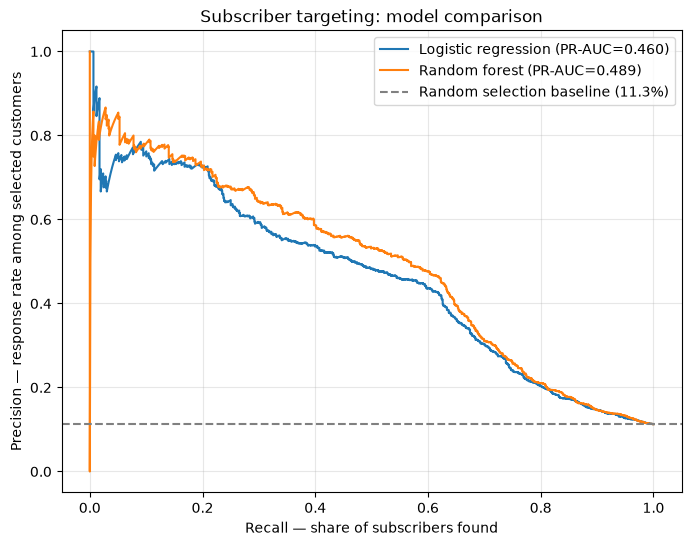

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8, 6))

for name, scores in [
    ("Logistic regression", probabilities),
    ("Random forest", forest_probabilities)
]:
    precision, recall, _ = precision_recall_curve(y_test_random, scores)
    ap = average_precision_score(y_test_random, scores)
    plt.plot(recall, precision, label=f"{name} (PR-AUC={ap:.3f})")

plt.axhline(
    y_test_random.mean(),
    color="gray",
    linestyle="--",
    label=f"Random selection baseline ({y_test_random.mean():.1%})"
)
plt.xlabel("Recall — share of subscribers found")
plt.ylabel("Precision — response rate among selected customers")
plt.title("Subscriber targeting: model comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Conclusion

The random forest performed slightly better than logistic regression on the stratified evaluation split. When selecting the 20% of customers with the highest scores, it reached 66.38% of subscribers, with a 37.4% response rate.

The later-period stress test showed that response rates changed substantially over time. The model’s top 20% had a 59.93% response rate in that period, but reached 38.86% of its subscribers. This means the model should be checked on recent data before being used for a real campaign.

Call duration was excluded because it is only known during or after a call. The model identifies historical patterns; it does not prove that contacting a customer causes them to subscribe. A randomized campaign experiment would be needed to measure causal impact.